##Step 1-Drive Mounting

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
CLEAN_DIR = os.path.join(BASE_DIR, "CLEAN_DATASET")
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")

def count_images(folder):
    if not os.path.isdir(folder):
        return "FOLDER NOT FOUND"

    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    return sum(
        1 for name in os.listdir(folder)
        if name.lower().endswith(extensions)
    )

for dataset_name, dataset_path in [
    ("Clean dataset", CLEAN_DIR),
    ("Training dataset", os.path.join(SPLIT_DIR, "train")),
    ("Testing dataset", os.path.join(SPLIT_DIR, "test")),
]:
    print(f"\n{dataset_name}:")
    for class_name in ["infected", "noninfected"]:
        folder = os.path.join(dataset_path, class_name)
        print(f"  {class_name}: {count_images(folder)}")


Mounted at /content/drive

Clean dataset:
  infected: 3150
  noninfected: 778

Training dataset:
  infected: 2520
  noninfected: 622

Testing dataset:
  infected: 630
  noninfected: 156


##Step 2 — Prepare the ResNet50 data loaders

In [ ]:

import os
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Dataset paths
BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")
TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ImageNet normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Testing transformations: no random augmentation
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Load images
train_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)
test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=test_transform
)

# Data loaders
train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=2
)
test_loader = DataLoader(
    test_dataset, batch_size=32,
    shuffle=False, num_workers=2
)

# Verify everything
print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

# Check one batch
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Device: cpu
Class mapping: {'infected': 0, 'noninfected': 1}
Training images: 3142
Testing images: 786
Training batches: 99
Testing batches: 25
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


##Step 3 — Load pretrained ResNet50

In [ ]:

import torch
import torch.nn as nn
from torchvision import models

# Use the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load ResNet50 with pretrained ImageNet weights
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Replace the final layer for our two classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

# Move the model to the selected device
model = model.to(device)

print("Model: ResNet50")
print("Pretrained weights: ImageNet")
print("Input features to final layer:", num_features)
print("Output classes:", model.fc.out_features)
print("Model loaded successfully.")


Device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 191MB/s]


Model: ResNet50
Pretrained weights: ImageNet
Input features to final layer: 2048
Output classes: 2
Model loaded successfully.


##Step 4 — Configure the loss function and optimizer

In [ ]:

import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Training configuration ready.")


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Trainable parameters: 23512130
Training configuration ready.


##Step 5 — Train ResNet50

In [ ]:

import time
import torch

NUM_EPOCHS = 5

train_history = []

for epoch in range(NUM_EPOCHS):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss and accuracy
        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total
    elapsed = time.time() - start_time

    train_history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    })

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}% | "
        f"Time: {elapsed/60:.2f} min"
    )

print("\nTraining completed.")


Epoch [1/5] Loss: 0.1652 | Accuracy: 93.22% | Time: 8.80 min
Epoch [2/5] Loss: 0.0358 | Accuracy: 99.14% | Time: 0.63 min
Epoch [3/5] Loss: 0.0235 | Accuracy: 99.33% | Time: 0.59 min
Epoch [4/5] Loss: 0.0208 | Accuracy: 99.52% | Time: 0.61 min
Epoch [5/5] Loss: 0.0142 | Accuracy: 99.65% | Time: 0.61 min

Training completed.


##Step 6 — Save your trained model first

In [ ]:

import os
import torch

SAVE_DIR = "/content/drive/MyDrive/PCOS_Project/model_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    SAVE_DIR, "resnet50_baseline.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "epochs_trained": 5,
    "image_size": 224
}, checkpoint_path)

print("Model saved successfully!")
print("Saved to:", checkpoint_path)
print("File size (MB):", round(
    os.path.getsize(checkpoint_path) / (1024 * 1024), 2
))


Model saved successfully!
Saved to: /content/drive/MyDrive/PCOS_Project/model_checkpoints/resnet50_baseline.pth
File size (MB): 90.0


##Step 7 — Evaluate ResNet50 on the test dataset

In [ ]:

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

print("Test images:", len(y_true))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["infected", "noninfected"],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print(
    "\nROC-AUC (noninfected as positive class):",
    round(roc_auc_score(y_true, y_prob[:, 1]), 4)
)


Test images: 786
Accuracy: 0.9873

Classification Report:
              precision    recall  f1-score   support

    infected     0.9921    0.9921    0.9921       630
 noninfected     0.9679    0.9679    0.9679       156

    accuracy                         0.9873       786
   macro avg     0.9800    0.9800    0.9800       786
weighted avg     0.9873    0.9873    0.9873       786

Confusion Matrix:
[[625   5]
 [  5 151]]

ROC-AUC (noninfected as positive class): 0.9984


Let's conduct a class-weighted ResNet50 experiment and compare it with  existing baseline. This will help us assess whether class weighting improves performance on the underrepresented noninfected class without sacrificing detection of the infected class.

training counts are 2,520 infected and 622 noninfected images. We'll use inverse-frequency class weights:
- infected: approximately 0.623
- noninfected: approximately 2.526

##Step 1 — Initialize the class-weighted model

In [ ]:

import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Confirm the GPU and existing data loaders
assert torch.cuda.is_available(), "GPU not available"
assert len(train_dataset) == 3142, "Unexpected training dataset size"
assert len(test_dataset) == 786, "Unexpected test dataset size"

device = torch.device("cuda")

# Load the saved baseline checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/resnet50_baseline.pth"
)
assert os.path.exists(checkpoint_path), "Baseline checkpoint not found"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Create a separate ResNet50 with the same architecture
weighted_model = models.resnet50(weights=None)
weighted_model.fc = nn.Linear(
    weighted_model.fc.in_features, 2
)
weighted_model.load_state_dict(checkpoint["model_state_dict"])
weighted_model = weighted_model.to(device)

# Calculate weights from training class counts
class_counts = torch.tensor([2520, 622], dtype=torch.float32)
class_weights = (
    class_counts.sum() / (len(class_counts) * class_counts)
).to(device)

# Weighted loss and a fresh optimizer
weighted_criterion = nn.CrossEntropyLoss(weight=class_weights)
weighted_optimizer = optim.Adam(
    weighted_model.parameters(), lr=0.0001
)

print("Starting checkpoint: ResNet50 baseline")
print("Device:", device)
print("Class mapping:", train_dataset.class_to_idx)
print("Class weights:", class_weights.cpu().tolist())
print("Weighted model initialized successfully.")


Starting checkpoint: ResNet50 baseline
Device: cuda
Class mapping: {'infected': 0, 'noninfected': 1}
Class weights: [0.6234126687049866, 2.525723457336426]
Weighted model initialized successfully.


##Step 2 — Train the class-weighted ResNet50

In [ ]:

import time
import torch
from IPython.display import clear_output

NUM_EPOCHS = 5
weighted_history = []

for epoch in range(NUM_EPOCHS):
    weighted_model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        weighted_optimizer.zero_grad()

        outputs = weighted_model(images)
        loss = weighted_criterion(outputs, labels)

        loss.backward()
        weighted_optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        # Show progress every 10 batches
        if (batch_idx + 1) % 10 == 0 or batch_idx + 1 == len(train_loader):
            print(
                f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(train_loader)} | "
                f"Loss so far: {running_loss / total:.4f}",
                flush=True
            )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total
    elapsed = (time.time() - start_time) / 60

    weighted_history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    })

    print(
        f"COMPLETED Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}% | "
        f"Time: {elapsed:.2f} min\n",
        flush=True
    )

print("Class-weighted training completed.")


Epoch 1/5 | Batch 10/99 | Loss so far: 0.0487
Epoch 1/5 | Batch 20/99 | Loss so far: 0.0285
Epoch 1/5 | Batch 30/99 | Loss so far: 0.0203
Epoch 1/5 | Batch 40/99 | Loss so far: 0.0187
Epoch 1/5 | Batch 50/99 | Loss so far: 0.0182
Epoch 1/5 | Batch 60/99 | Loss so far: 0.0333
Epoch 1/5 | Batch 70/99 | Loss so far: 0.0332
Epoch 1/5 | Batch 80/99 | Loss so far: 0.0312
Epoch 1/5 | Batch 90/99 | Loss so far: 0.0319
Epoch 1/5 | Batch 99/99 | Loss so far: 0.0298
COMPLETED Epoch [1/5] | Loss: 0.0298 | Accuracy: 99.43% | Time: 0.64 min

Epoch 2/5 | Batch 10/99 | Loss so far: 0.0045
Epoch 2/5 | Batch 20/99 | Loss so far: 0.0142
Epoch 2/5 | Batch 30/99 | Loss so far: 0.0137
Epoch 2/5 | Batch 40/99 | Loss so far: 0.0128
Epoch 2/5 | Batch 50/99 | Loss so far: 0.0218
Epoch 2/5 | Batch 60/99 | Loss so far: 0.0204
Epoch 2/5 | Batch 70/99 | Loss so far: 0.0192
Epoch 2/5 | Batch 80/99 | Loss so far: 0.0180
Epoch 2/5 | Batch 90/99 | Loss so far: 0.0189
Epoch 2/5 | Batch 99/99 | Loss so far: 0.0211
COMPLE

##Step 3 — Save the class-weighted model

In [ ]:

import os
import torch

SAVE_DIR = "/content/drive/MyDrive/PCOS_Project/model_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

weighted_checkpoint_path = os.path.join(
    SAVE_DIR, "resnet50_class_weighted.pth"
)

torch.save({
    "model_state_dict": weighted_model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "class_weights": class_weights.cpu().tolist(),
    "epochs_trained": 5,
    "image_size": 224
}, weighted_checkpoint_path)

print("Class-weighted model saved successfully!")
print("Saved to:", weighted_checkpoint_path)
print(
    "File size (MB):",
    round(os.path.getsize(weighted_checkpoint_path) / (1024 * 1024), 2)
)


Class-weighted model saved successfully!
Saved to: /content/drive/MyDrive/PCOS_Project/model_checkpoints/resnet50_class_weighted.pth
File size (MB): 90.0


##Step 4 — Evaluate the class-weighted model

In [ ]:

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from torchvision import models
import torch.nn as nn

# Rebuild the model architecture
weighted_eval_model = models.resnet50(weights=None)
weighted_eval_model.fc = nn.Linear(
    weighted_eval_model.fc.in_features, 2
)

# Load saved class-weighted checkpoint
checkpoint = torch.load(
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/resnet50_class_weighted.pth",
    map_location=device,
    weights_only=True
)

weighted_eval_model.load_state_dict(
    checkpoint["model_state_dict"]
)
weighted_eval_model = weighted_eval_model.to(device)
weighted_eval_model.eval()

# Evaluate on the same test set
y_true_weighted = []
y_pred_weighted = []
y_prob_weighted = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = weighted_eval_model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        y_true_weighted.extend(labels.numpy())
        y_pred_weighted.extend(predictions.cpu().numpy())
        y_prob_weighted.extend(probabilities.cpu().numpy())

y_true_weighted = np.array(y_true_weighted)
y_pred_weighted = np.array(y_pred_weighted)
y_prob_weighted = np.array(y_prob_weighted)

print("Test images:", len(y_true_weighted))
print(
    "Accuracy:",
    round(accuracy_score(y_true_weighted, y_pred_weighted), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_true_weighted,
    y_pred_weighted,
    labels=[0, 1],
    target_names=["infected", "noninfected"],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true_weighted, y_pred_weighted, labels=[0, 1]
))

print(
    "\nROC-AUC (noninfected as positive class):",
    round(roc_auc_score(
        y_true_weighted, y_prob_weighted[:, 1]
    ), 4)
)


Test images: 786
Accuracy: 0.9873

Classification Report:
              precision    recall  f1-score   support

    infected     0.9921    0.9921    0.9921       630
 noninfected     0.9679    0.9679    0.9679       156

    accuracy                         0.9873       786
   macro avg     0.9800    0.9800    0.9800       786
weighted avg     0.9873    0.9873    0.9873       786

Confusion Matrix:
[[625   5]
 [  5 151]]

ROC-AUC (noninfected as positive class): 0.9988


class weighting is a valid technique, but in this experiment it did not change the test-set classifications. We should preserve both results and continue with a fair, consistent comparison rather than assume the weighted model is better.

##Step 15: Plot ResNet50 confusion matrix and ROC–AUC curve

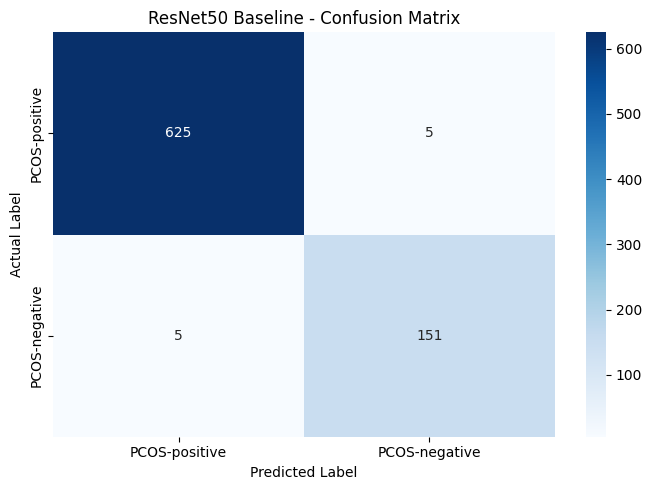

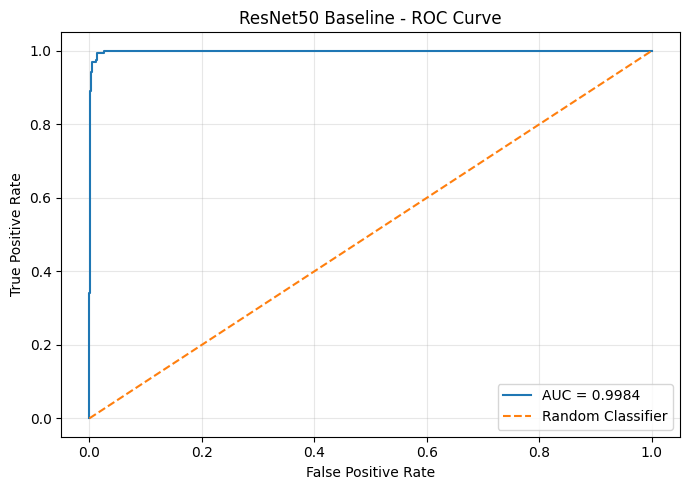


ResNet50 Baseline
Confusion matrix:
 [[625   5]
 [  5 151]]
ROC-AUC: 0.9984


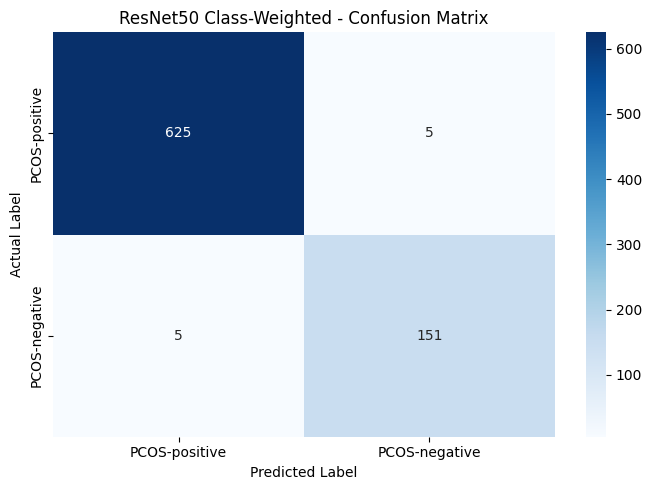

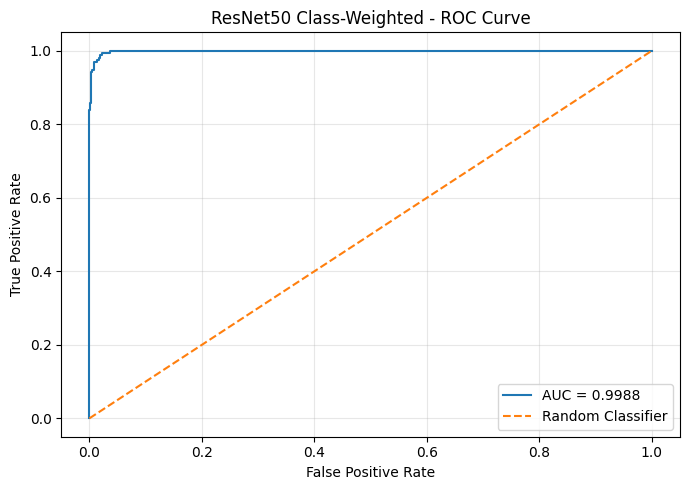


ResNet50 Class-Weighted
Confusion matrix:
 [[625   5]
 [  5 151]]
ROC-AUC: 0.9988

All ResNet50 evaluation plots saved successfully.


In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import models
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

PLOT_DIR = "/content/drive/MyDrive/PCOS_Project"
CHECKPOINT_DIR = os.path.join(PLOT_DIR, "model_checkpoints")

def plot_resnet_results(checkpoint_name, title_prefix, file_prefix):
    # Rebuild ResNet50
    plot_model = models.resnet50(weights=None)
    plot_model.fc = nn.Linear(plot_model.fc.in_features, 2)

    checkpoint_path = os.path.join(CHECKPOINT_DIR, checkpoint_name)
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    plot_model.load_state_dict(checkpoint["model_state_dict"])
    plot_model = plot_model.to(device)
    plot_model.eval()

    y_true, y_pred, y_prob = [], [], []

    # Predict using the existing test loader
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            probabilities = torch.softmax(plot_model(images), dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(probabilities.argmax(dim=1).cpu().numpy())
            y_prob.extend(probabilities[:, 1].cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["PCOS-positive", "PCOS-negative"],
        yticklabels=["PCOS-positive", "PCOS-negative"]
    )
    plt.title(f"{title_prefix} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOT_DIR, f"{file_prefix}_confusion_matrix.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    # ROC curve (class 1 = noninfected / PCOS-negative)
    fpr, tpr, _ = roc_curve(y_true, y_prob, pos_label=1)
    auc_score = roc_auc_score(y_true, y_prob)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{title_prefix} - ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOT_DIR, f"{file_prefix}_roc_curve.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print(f"\n{title_prefix}")
    print("Confusion matrix:\n", cm)
    print(f"ROC-AUC: {auc_score:.4f}")


# Generate all four plots
plot_resnet_results(
    "resnet50_baseline.pth",
    "ResNet50 Baseline",
    "resnet50_baseline"
)

plot_resnet_results(
    "resnet50_class_weighted.pth",
    "ResNet50 Class-Weighted",
    "resnet50_weighted"
)

print("\nAll ResNet50 evaluation plots saved successfully.")